# Exploration of h5 file and basic SENSE (Sensitivity Encoding)



In [39]:
import numpy as np
import h5py
from matplotlib import pyplot as plt
import scipy.io as sio
import sigpy as sp
import sigpy.mri as mri
import sigpy.mri.app as app

"""# Display Multiple Outputs in Jupyter Notebook Cells
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"""

#to visualize header xml
import lxml.etree as etree

# load defined functions from utils.py
from utils import *
from rum_metrics_SL import run_all_metrics

# Loading file, getting k space data, performing perform 2-D inverse discrete Fourier Transform to get image and reshape to 320x320

In [40]:
#loading .h5 file with The h5py package (Pythonic interface to the HDF5 binary data format) as a h5py._hl.files.File
file_path = "data/file_brain_AXT2_205_2050058.h5"
hf = h5py.File(file_path)

##  Getting kspace data, correct height and perform 2-D inverse discrete Fourier Transform to get images.
- kspace are in h5py._hl.dataset.Dataset format  <br>
"kspace": shape (16, 20, 640, 320) from ismrmrd_header : matrixSize 640 x; y 320; z1 Number of coils = 20  == receiverChannels
receiverChannels <br>
- height is 640 and width 320, reshape from (16, 20, 640, 320) to (16, 20, 320, 320)
- then perform 2-D inverse discrete Fourier Transform.


In [41]:
# getting kspace data
volume_kspace = hf['kspace']
print(f"k_space_data shape : {volume_kspace.shape}")

# getting image from kspace data
img_from_kspace = inverse_fft2_shift_all_splices(volume_kspace)

# flip the image upside down to get front on top of axial images (convention) 
img_from_kspace = np.flip(img_from_kspace, axis= 2)  
img_from_kspace.shape

k_space_data shape : (16, 20, 640, 320)
(16, 20, 640, 320)


(16, 20, 640, 320)

### Remove 2x readout oversampling size of images from 640x320 to 320x320

In [42]:
# Determine the size of the 2th dimension -> remove 2x readout over-sampling
dim2_size = img_from_kspace.shape[2]
# Calculate the start and end indices for cropping
start_idx = (dim2_size - 320) // 2
end_idx = start_idx + 320
print(f"start index : {start_idx} and end index : {end_idx}")
# Crop the middle 320 points in the 0th dimension
img_from_kspace_cropped = img_from_kspace[ :, :, start_idx:end_idx, :]
img_from_kspace_cropped.shape

start index : 160 and end index : 480


(16, 20, 320, 320)

# Handling multi-coil data
- perform rsos function that combine multi-coil images into a single image by computing the pixel-wise root-sum-of-squares across the coil dimension.
- plot the combined images

## Rss coil combination = ground truth to compare to reconstruction techniques not involving coil sensitivity

In [43]:
# rsos function that combine multi-coil images into a single image by computing 
# the pixel-wise root-sum-of-squares across the coil dimension.
print(img_from_kspace_cropped.shape)
img_cropped_rsos = rsos(img_from_kspace_cropped, 1)
print(f"image rss combined shape : {img_cropped_rsos.shape}")
print(f"number of slices : {np.abs(img_cropped_rsos).shape[0]}")

(16, 20, 320, 320)
image rss combined shape : (16, 320, 320)
number of slices : 16


## Plot the RSS coil combined images for the 16 slices

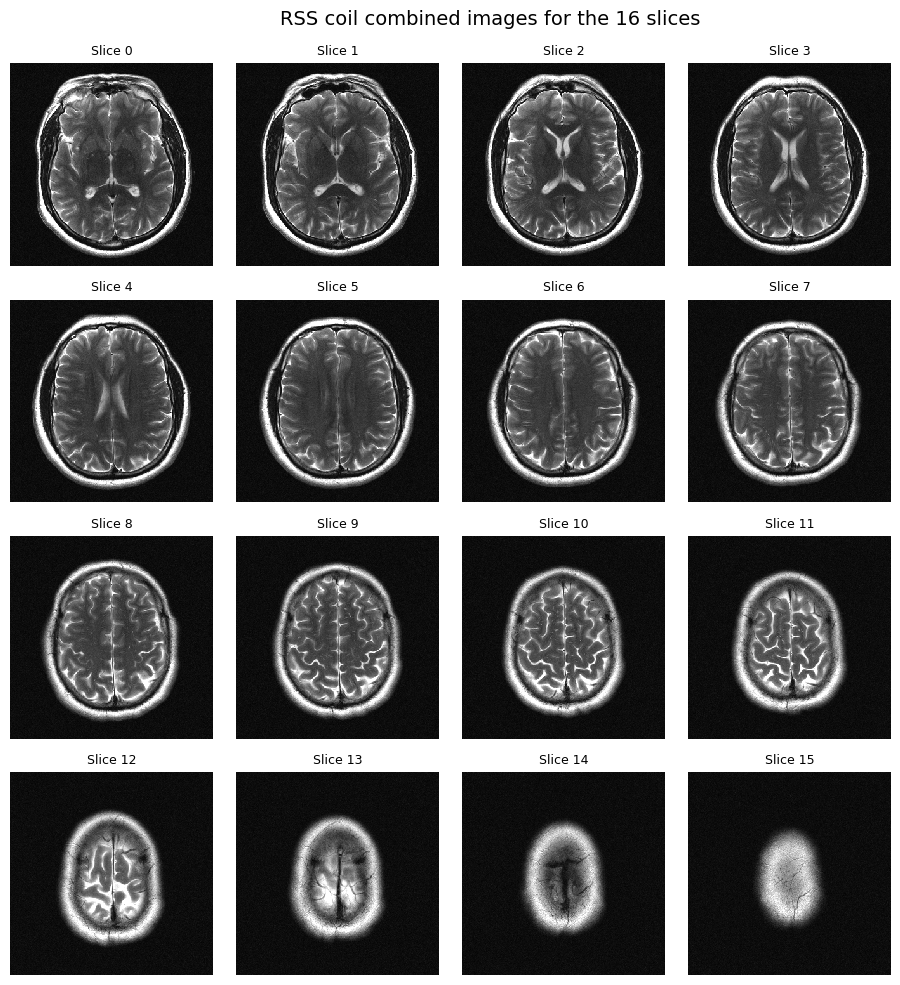

In [44]:
show_grid(np.abs(img_cropped_rsos), cmap='gray',set_vmax=5e-4, nrows=4, ncols=4,type="Slice", title= "RSS coil combined images for the 16 slices",fig_size=(10,10))

## Getting and plotting kspace and image from the middle slice (8th)

In [45]:
 # Choosing the middle slice of this volume
# get images from the 8st slice for all coils
img_8st_slice = img_from_kspace_cropped[7,:,:,:]
# get image from the 8th slice rss coils combined
img_8st_slice_rss = img_cropped_rsos[7,:,:]
# reconstruct kspace from image as the image was cropped
kspace_8st_slice = ft2_np(img_8st_slice)
# combine signal from all coils
kspace_8st_slice_rsos = rsos(kspace_8st_slice, 0)

### Separate plots

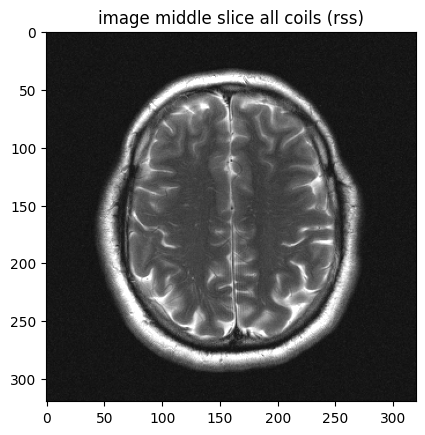

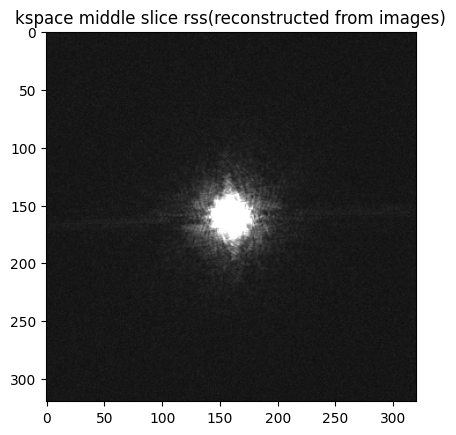

In [46]:
plt.imshow(img_8st_slice_rss, cmap="gray")
plt.title('image middle slice all coils (rss)')
plt.clim(0,5e-4)
plt.show()


# plot and adjust min and max values with clim
plt.imshow(kspace_8st_slice_rsos, cmap="gray")
plt.title('kspace middle slice rss(reconstructed from images)')
plt.clim(0,5e-4)

### Combined plots

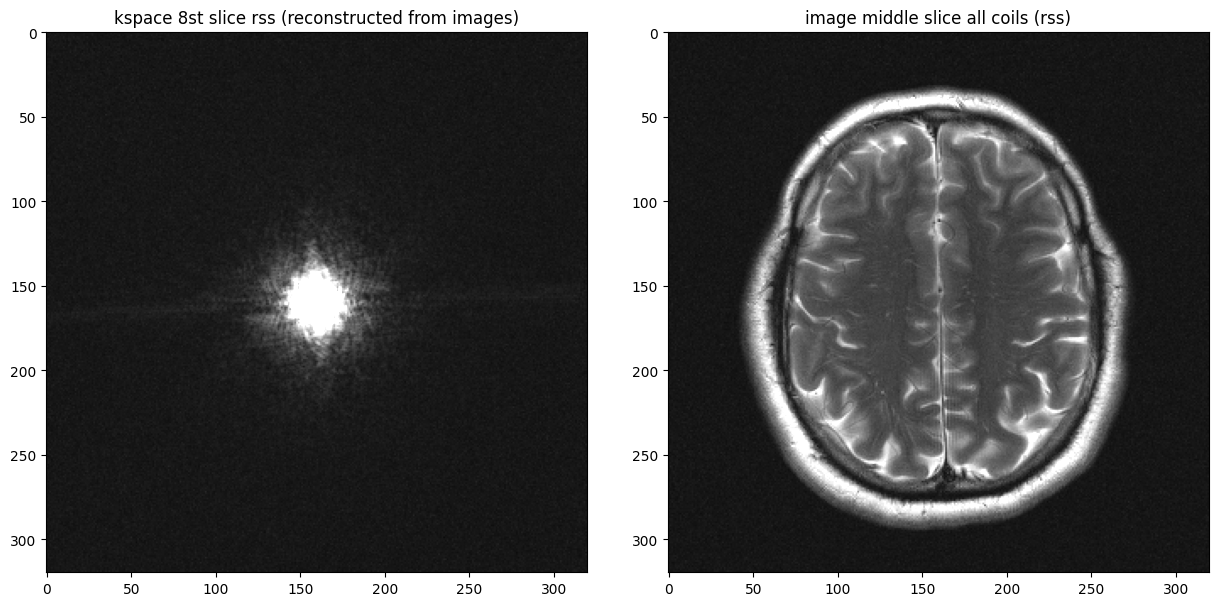

In [47]:
# Create a figure with 3 rows and 1 column
fig, axs = plt.subplots(1, 2, figsize=(15, 8))

# Plot on the first subplot
axs[0].imshow(kspace_8st_slice_rsos, cmap="gray", vmin=0, vmax=5e-4)
axs[0].set_title('kspace 8st slice rss (reconstructed from images)')

# Plot on the second subplot
axs[1].imshow(img_8st_slice_rss, cmap="gray", vmin=0, vmax=5e-4)
axs[1].set_title('image middle slice all coils (rss)')

# Adjust spacing between subplots
plt.subplots_adjust(wspace=0.15, hspace=0)

# Display the plot
plt.show()

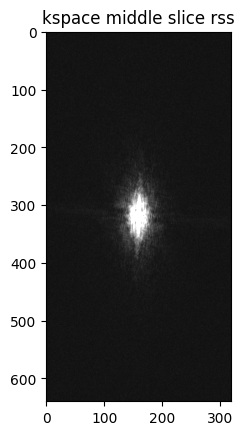

In [48]:
# get kspace from the 8st slice for all coils
kspace_8st_slice_original = volume_kspace[7,:,:,:]
# combine signal from all coils
kspace_8st_slice_original_rsos = rsos(kspace_8st_slice_original, 0)

# plot and adjust min and max values with clim
plt.imshow(kspace_8st_slice_original_rsos, cmap="gray")
plt.title('kspace middle slice rss')
plt.clim(0,5e-4)

## Save numpy arrays to use them in other files
[Tuto](https://medium.com/@prathik.codes/how-to-save-numpy-arrays-to-file-and-load-them-later-271396d1683c) to save and load numpy file

In [49]:
# save cropped 320x320 images from the 8st slice for all coils
np.save("data/img_8st_slice.npy",img_8st_slice)

# save cropped 320x320 images from the 8st slice rss coils combined
np.save("data/img_8st_slice_rss.npy",img_8st_slice_rss)

# save reconstruct kspace from cropped imge for the 8st slice for all coils
np.save("data/kspace_8st_slice.npy",kspace_8st_slice)

# save reconstruct kspace from cropped imge for the 8st slice rss coils combined
np.save("data/kspace_8st_slice_rsos.npy",kspace_8st_slice_rsos)

# Compute coil sensitivity maps using ESPIRiT
[Paper](https://pubmed.ncbi.nlm.nih.gov/23649942/) and 
[Library](https://sigpy.readthedocs.io/en/latest/generated/sigpy.mri.app.EspiritCalib.html#sigpy.mri.app.EspiritCalib) links

EspiritCalib: 100%|██████████| 100/100 [00:04<00:00, 24.16it/s]


Sensitivity maps shape: (20, 320, 320)


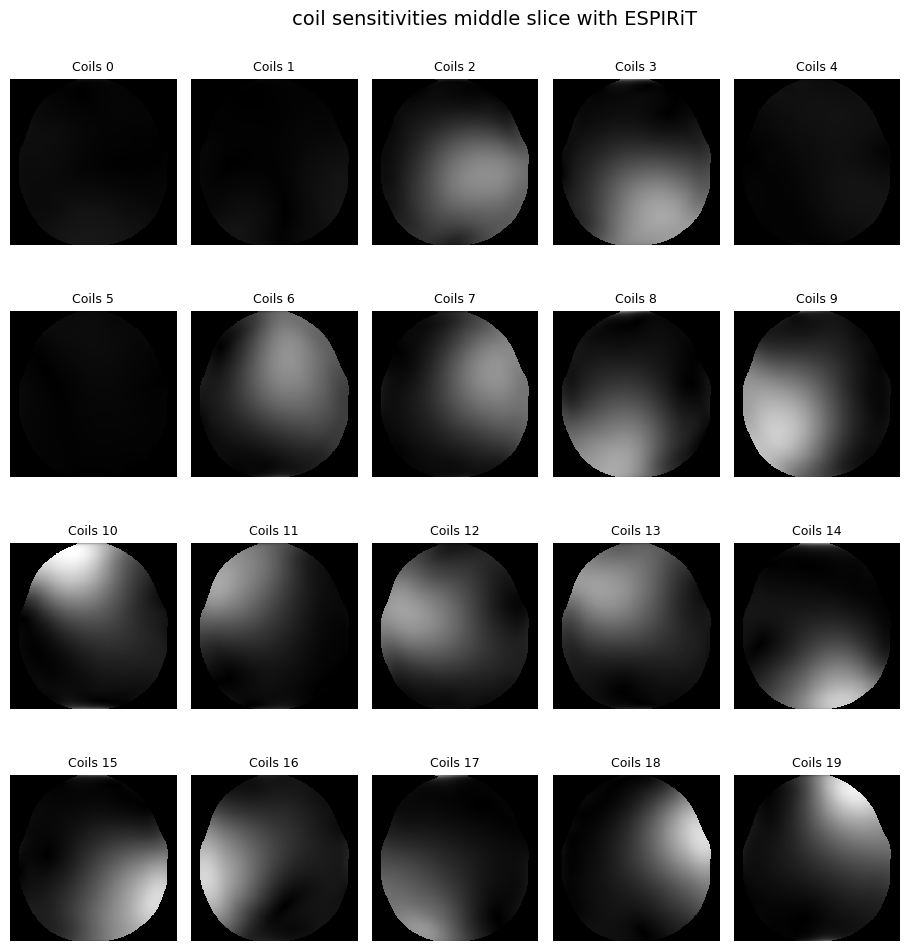

In [50]:
# coils are in the 0th dimension for EspitirCalib app

calib_region = 24   # Calibration region size
crop_size = 0.8     # threshold for cropping the sensitivity maps
device = sp.Device(-1)  # Use CPU 

sensitivity_maps_8st_slice = app.EspiritCalib(kspace_8st_slice, calib_width=calib_region, device=device, crop=crop_size).run()

# save sensitivity maps
np.save("data/sensitivity_maps_8st_slice.npy",sensitivity_maps_8st_slice)

print("Sensitivity maps shape:", sensitivity_maps_8st_slice.shape)  # [num_coils, height, width]

show_grid(np.abs(sensitivity_maps_8st_slice), cmap='gray', nrows=4, ncols=5, type="Coils", title= "coil sensitivities middle slice with ESPIRiT",fig_size=(10,10))

### Test modify VMax in show grid function

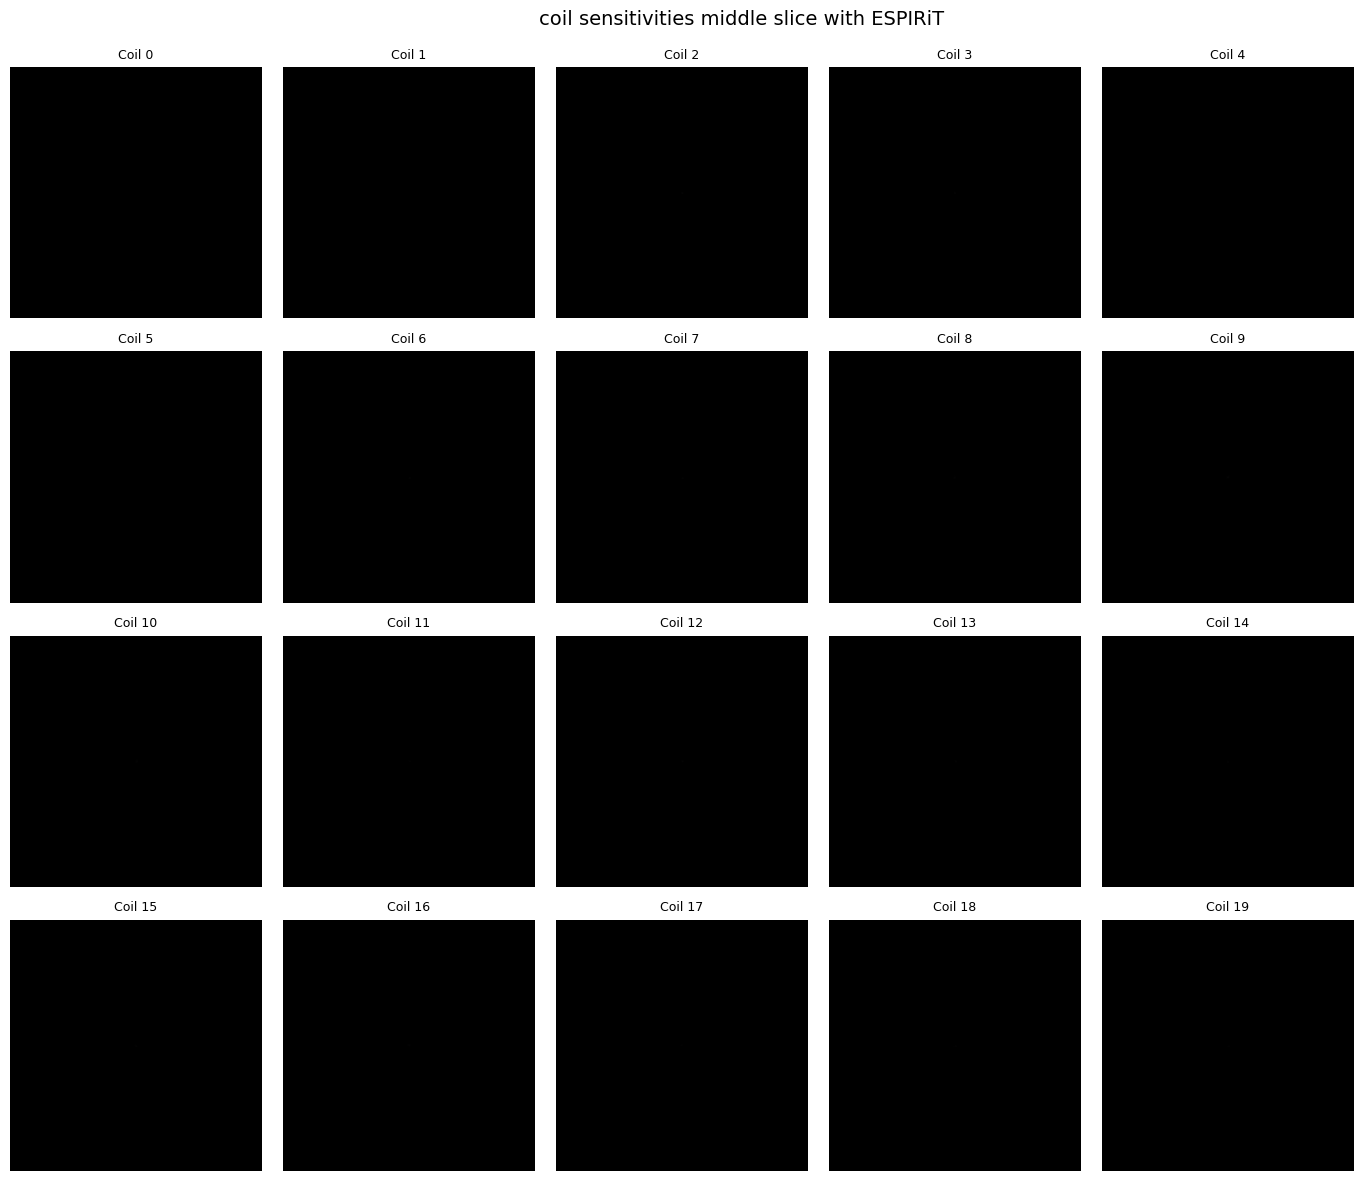

In [52]:
show_grid(np.abs(kspace_8st_slice_accl), cmap='gray',set_vmax= 0.4, nrows=4, ncols=5,type="Coil", title= "coil sensitivities middle slice with ESPIRiT",fig_size=(15,12))

## Sensitivity-weighted coil combination wih full sampled kspace == "Simple Sense style coil combination" 
Inputs: img_8st_slice and sensitivity_maps_8st_slice — both are complex arrays with shape (nx, ny, nCoils) (320,320,20).

[numpy.conj](https://numpy.org/doc/stable/reference/generated/numpy.conj.html) Return the complex conjugate, element-wise. The complex conjugate of a complex number is obtained by changing the sign of its imaginary part. <br>
Operation: np.conj(sensitivity_maps_8st_slice) takes the complex conjugate of the sensitivity maps. <br>

The * does element-wise multiplication between each coil image and that coil's conjugated sensitivity.

Sum: np.sum(..., 0) sums over axis 0 (the coil dimension), producing an array of shape (nx, ny).

Interpretation: This computes a SENSE-style coil combination (matched‑filter): for each pixel m(x,y) = sum_c img_c(x,y) * conj(s_c(x,y)). The result is a single complex image.

Why conjugate: Multiplying by the complex conjugate aligns coil phases and applies coil weighting so signals add constructively.

Note: This is a simple coil combination (matched-filter). A full SENSE reconstruction or optimal least-squares coil combine may include normalization by sum_c |s_c|^2 or explicit unfolding for under-sampled data.

### key differences between sensitivity-weighted combination and root sum of squares (RSS) combination
1. Phase Information : 
    RSS: Loses all phase information (magnitude-only)<br>
    Sensitivity-weighted: Preserves phase information (complex-valued result)
2. SNR Optimality : 
    RSS: Suboptimal SNR, especially when coil sensitivities vary significantly <br>
    Sensitivity-weighted: Optimal SNR - weights coils by their local sensitivity
3. Coil Sensitivity Weighting   
    RSS: Treats all coils equally <br>
    Sensitivity-weighted: Weights coils based on their sensitivity maps (stronger signal from more sensitive coils gets higher weight)
4. Intensity Bias<br>
    RSS: Can create intensity variations across the image based on coil geometry (brighter near coils, darker far from coils) <br>
    Sensitivity-weighted: Corrects for coil sensitivity variations, producing more uniform intensity
5. Requirements
    RSS: No additional information needed <br>
    Sensitivity-weighted: Requires coil sensitivity maps (must be estimated or measured separately)

Full sample image coils combination w/ sense maps


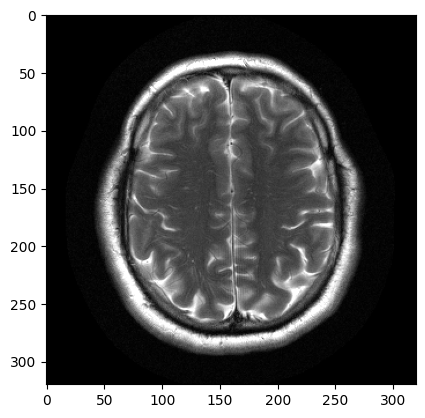

In [ ]:
img_8st_slice_sensi_all_coils = np.sum(img_8st_slice * np.conj(sensitivity_maps_8st_slice),0)
print('Full sample image coils combination w/ sense maps')
plt.imshow(np.abs(img_8st_slice_sensi_all_coils), cmap="gray")
plt.clim(0,5e-4)

## Sensitivity-weighted combination wih normalization on full sampled kspace = ground truth for all recon methods involving coil sensitivity
ideal or gold standard used in Loraks SENSE.<br>
The normalized version of previous sensitivity-based combination that has : 
Uniform intensity across the image; 
Compensates for varying coil sensitivity coverage; 
More appropriate for quantitative imaging; <br><br>
Operations : 
- (abs(coil_sens)**2).sum(0) : Computes magnitude squared of sensitivity maps. Sums across coils
This normalizes by the total coil sensitivity energy at each pixel

- np.finfo(float).eps : Adds machine epsilon (smallest representable float)
Prevents division by zero in regions with no coil sensitivity


Full samle image coils comb w/ sense maps + norm


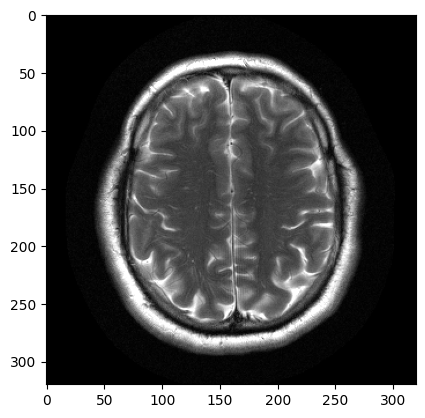

In [ ]:
image_FS_SENSE_Norm = (sensitivity_maps_8st_slice.conj()*img_8st_slice).sum(0) / ((abs(sensitivity_maps_8st_slice)**2).sum(0)+np.finfo(float).eps)
print('Full samle image coils comb w/ sense maps + norm')
plt.imshow(np.abs(image_FS_SENSE_Norm), cmap="gray")
plt.clim(0,5e-4)

# Creating Undersampled kspace

## Create mask to perform undersampling : sampling pattern cartesian with variable density (center region preserved)
create a mask with values = 1 each 4 rows + in the center region of the image

### Code to produce mask, plot it and calculate the real acceleration factor 

Mask shape : (320, 320, 1)
actual acceleration factor: 3.265


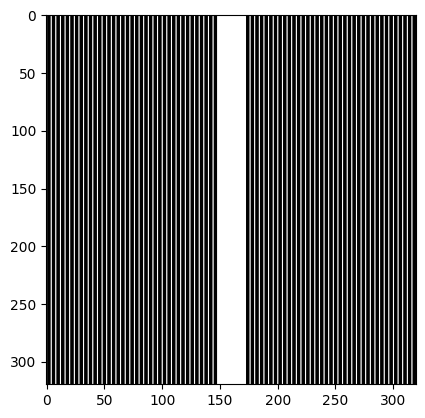

In [28]:
# Creating the mask

accel = 4   # acceleration factor
calib_region = 24 # used to create Sensitivity map

# Getting the shape of kspace from 1 coil and saving it as tuple
img_shape = sensitivity_maps_8st_slice[0,:,:].shape

# Creating a mask filled with 0 with shape of img_shape
msk = np.zeros(img_shape, dtype=float)  # Initialize with the correct shape

# Fill with 1 each accel element, here each 4 element
msk[:, 0::accel] = 1   

# include the center of k-space with calibration region size 
center_region = calib_region  # Size of the center region to keep
# modify the mask with 1 in the center region
msk[:, img_shape[1]//2 - center_region//2:img_shape[1]//2 + center_region//2] = 1
# Add dimensions to match kspace that is 3d array to have shape (320, 320, 1)
msk = msk[..., np.newaxis] 
# save mask
np.save("data/msk.npy",msk)
print(f"Mask shape : {msk.shape}")
# Plot
plt.imshow(msk[:,:,0], cmap="gray")

# real calculated acceleration factor calculated by dividing the value of the mask if all values are 1 by actual sum of values with 0 and 1
# np.prod Return the product of array elements over a given axis
accl_factor = np.prod(msk.shape)/ np.sum(msk) 
print(f"actual acceleration factor: {accl_factor:.3f}")

In [29]:
unique, counts = np.unique(msk[0], return_counts=True)
print(f"uniques values : {unique} and respective counts : {counts}")

uniques values : [0. 1.] and respective counts : [222  98]


## 4X undersampling kspace and images on middle slice
zero fill reconstruction by multiplying kspace and mask to create kspace 4 x undersampled and corresponding image and RSS coil combination image of middle slice

In [30]:
# Need to transpose the mask to fit to kspace shape
print(f"mask shape : {msk.shape}")
print(f"kspace_8st_slice shape : {kspace_8st_slice.shape}")
# undersample k-space data with 0 values each 3 values and kept values 1 in 4 and the middle
kspace_8st_slice_accl = kspace_8st_slice * np.transpose(msk, (2,0,1))  
print(kspace_8st_slice_accl.shape)

# inverse Fourier transform from kspace to image
img_8st_slice_accl = inverse_fft2_shift_1slice(kspace_8st_slice_accl)
print(img_8st_slice_accl.shape)

mask shape : (320, 320, 1)
kspace_8st_slice shape : (20, 320, 320)
(20, 320, 320)
(20, 320, 320)


In [31]:
#plt.imshow(np.abs(img_8st_slice_accl[9,:,:]))

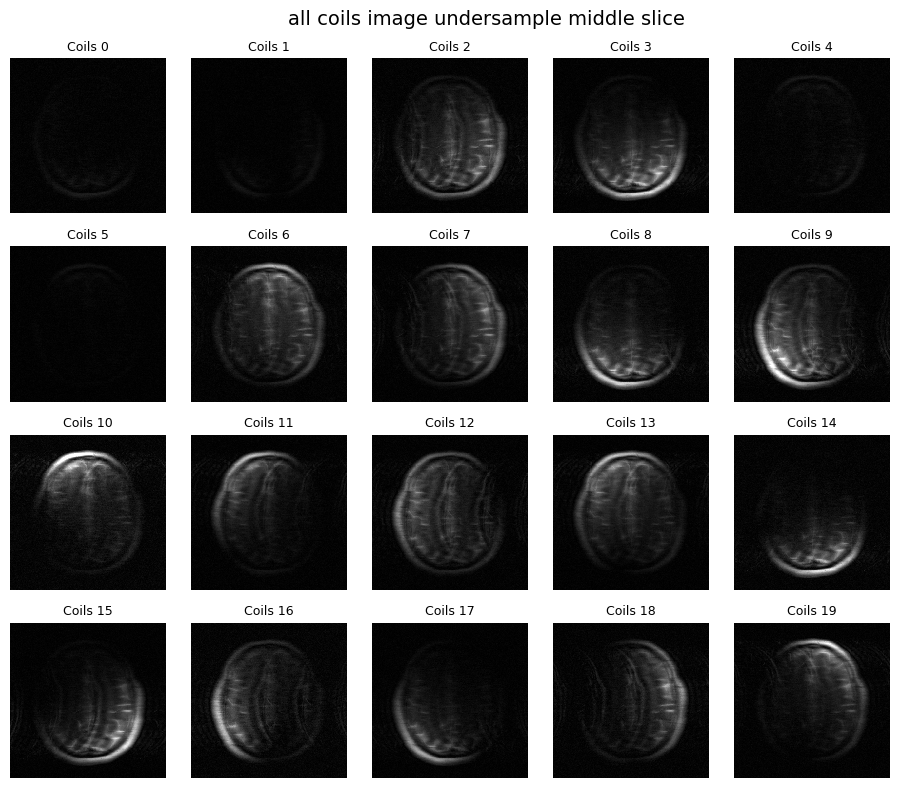

In [32]:
#def show_grid(data, coil_indices=None, cmap='viridis', set_vmax= None,nrows=4, ncols=5, type ="Coil" ,title = 'Signal from the 20 coils on 1 middle slice',fig_size=(12,9)):
show_grid(np.abs(img_8st_slice_accl), cmap='gray', set_vmax= 3e-4,nrows=4, ncols=5, type="Coils", title= "all coils image undersample middle slice ",fig_size=(10,8))

# Reconstruction

## Metrics evaluation
For the quantitative evaluation metric, we chose to use SSIM [45], with a script showing the script used for evaluation in the fastMRI repository at https://github.com/facebookresearch/fastMRI. SSIM has several parameters. We investigated adjusting these parameters prior to challenge launch, but found that they generally did not alter the ranking of methods evaluated in our quality control phase, and so as a result we used the default parameters in scikit-image [49].
[Link](https://pmc.ncbi.nlm.nih.gov/articles/PMC8428775/) <br>
the commonly used fidelity metrics, such as mean squared error (MSE), structural similarity (SSIM), and peak signal-to-noise ratio (PSNR). [Link](https://pmc.ncbi.nlm.nih.gov/articles/PMC11200466/) <br>

**Reference images?** <br>
For the ground truth images , we followed the previous convention [27] to use root sum-of-squares images. The advantage of this approach is that it does not bias to any one method for coil sensitivity estimation. There are some drawbacks to RSS, including 1) discarding of the phase information and 2) RSS images can have substantial noise in the background. The phase is not typically used for anatomical evaluation. The issue with noise is more fundamental as it is treated as ground truth in our quantitative evaluation, and any deviations from it influence our ranking. <br>
[Link](https://pmc.ncbi.nlm.nih.gov/articles/PMC8428775/)

## RSS coil combination  on 4X undersampled images on middle slice

In [33]:
# rss coil combine image
img_zf_8th_slice_rsos = rsos(img_8st_slice_accl, 0)
metrics_r4_rss = run_all_metrics(img_8st_slice_rss, img_zf_8th_slice_rsos)


Calculating MSE...
Calculating NRMSE...
Calculating PSNR...
Calculating SSIM...

METRICS RESULTS
MSE            : 0.0000
NRMSE          : 0.2013
PSNR           : 26.9191
SSIM           : 0.7767



zero fill NRMSE ref FS RSS:  20.131075995454168  %
NRMSE R4 ref FS RSS: 0.272 %'
RMSE R4 ref FS RSS: 0.0000 '
4x undersampled image middle slice all coils (rss)
(320, 320)


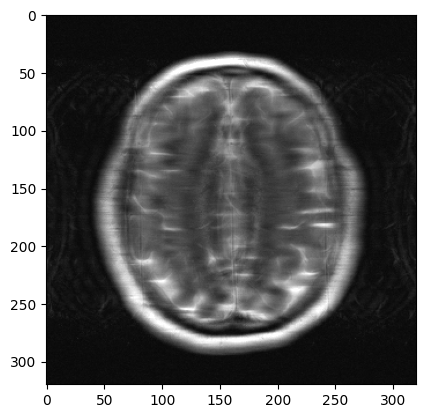

In [34]:


# calculate the Root Mean Squared Error
nrmse_old_r4_rss = nrmse(img_zf_8th_slice_rsos, img_8st_slice_rss)
print('zero fill NRMSE ref FS RSS: ', nrmse_old_r4_rss, ' %')

# def calculate_nrmse(actual, predicted):
nrmse_r4_rss = calculate_nrmse(img_8st_slice_rss, img_zf_8th_slice_rsos)
print(f"NRMSE R4 ref FS RSS: {nrmse_r4_rss:.3f} %'")

# def calculate_rmse(actual, predicted):
rmse_r4_rss = calculate_rmse(img_8st_slice_rss, img_zf_8th_slice_rsos)
print(f"RMSE R4 ref FS RSS: {rmse_r4_rss:.4f} '")

# print image title
print('4x undersampled image middle slice all coils (rss)')
print(img_zf_8th_slice_rsos.shape)

plt.imshow(img_zf_8th_slice_rsos, cmap="gray")
#plt.title('4x undersampled image middle slice all coils (rss)')
plt.clim(0,5e-4)

## SENSE style coil combination of 4X undersampled images on middle slice

In [38]:
# coil combine with estimated sensitivities
img_8stslice_acc_sensi_all_coils = np.sum(img_8st_slice_accl * np.conj(sensitivity_maps_8st_slice), 0)
metrics_r4_sensi = run_all_metrics(img_8st_slice_sensi_all_coils, img_8stslice_acc_sensi_all_coils)

NameError: name 'img_8st_slice_sensi_all_coils' is not defined

title : 4X accelerated image coils combination w/ sense maps
zero fill RMSE ref FS RSS: 128.180 %'


NameError: name 'img_8st_slice_sensi_all_coils' is not defined

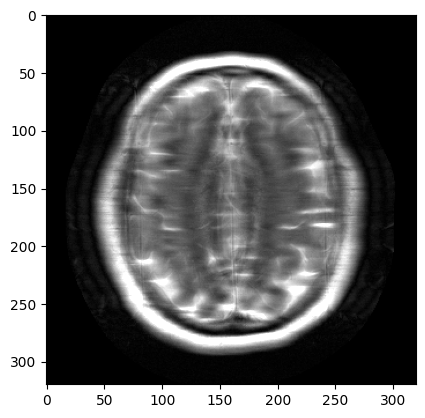

In [36]:
# coil combine with estimated sensitivities
img_8stslice_acc_sensi_all_coils = np.sum(img_8st_slice_accl * np.conj(sensitivity_maps_8st_slice), 0)

print("title : 4X accelerated image coils combination w/ sense maps")
plt.imshow(np.abs(img_8stslice_acc_sensi_all_coils), cmap='gray')
plt.clim(0,4e-4)

# calculate the Root Mean Squared Error
rmse_zf = nrmse(img_8stslice_acc_sensi_all_coils, img_8st_slice_rss)
print(f"zero fill RMSE ref FS RSS: {rmse_zf:.3f} %'")
rmse_zf_sense = nrmse(img_8stslice_acc_sensi_all_coils, img_8st_slice_sensi_all_coils)
print(f"zero fill RMSE ref img sense style: {rmse_zf_sense:.3f} %'")


# def calculate_nrmse(actual, predicted):
nrmse_r4_rss = calculate_nrmse(img_8st_slice_sensi_all_coils, img_8stslice_acc_sensi_all_coils)
print(f"NRMSE R4 ref FS img sense style: {nrmse_r4_rss:.3f} %'")

# def calculate_rmse(actual, predicted):
rmse_r4_rss = calculate_rmse(img_8st_slice_sensi_all_coils, img_8stslice_acc_sensi_all_coils)
print(f"RMSE R4 ref FS img sense style: {rmse_r4_rss:.4f} '")


In [37]:
print("Title : error Sense Styl reco - FS SENSE Style")
plt.imshow(np.abs(img_8stslice_acc_sensi_all_coils - img_8st_slice_sensi_all_coils), cmap='gray')
plt.clim(0,1e-4)

Title : error Sense Styl reco - FS SENSE Style


NameError: name 'img_8st_slice_sensi_all_coils' is not defined

## Sensitivity-weighted combination wih normalization on 4X undersampled images on middle slice
coil combine with estimated sensitivities and normalization

In [ ]:
image_US_SENSE_Norm = (sensitivity_maps_8st_slice.conj()*img_8st_slice_accl).sum(0) / ((abs(sensitivity_maps_8st_slice)**2).sum(0)+np.finfo(float).eps)
metrics_r4_sense_norm = run_all_metrics(img_8st_slice_sensi_all_coils, image_US_SENSE_Norm)

Converting ground truth image to magnitude (absolute value)...
Converting predicted image to magnitude (absolute value)...
Calculating MSE...
Calculating NRMSE...
Calculating PSNR...
Calculating SSIM...

METRICS RESULTS
MSE            : 0.0000
NRMSE          : 0.2031
PSNR           : 27.1402
SSIM           : 0.8196



title : 4X accelerated image coils combination w/ sense maps
zSensitivity + norm 4X accelerated RMSE ref FS RSS:: 128.180 %'
Sensitivity + norm 4X accelerated ref img sense style:  21.41488908491595  %
NRMSE R4 Sensitivity + normref FS img sense style: 0.345 %'
RMSE R4 Sensitivity + norm ref FS img sense style: 0.0000 '


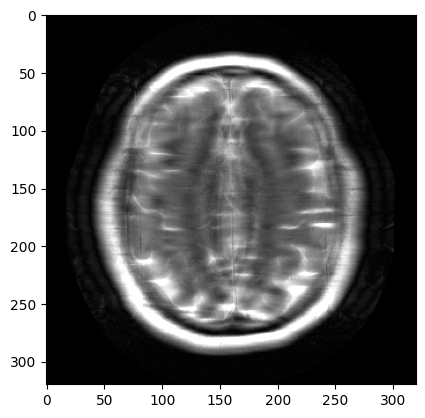

In [ ]:

print("title : 4X accelerated image coils combination w/ sense maps")
plt.imshow(np.abs(image_US_SENSE_Norm), cmap='gray')
plt.clim(0,4e-4)

# calculate the Root Mean Squared Error
rmse_r4_sensi_norm = nrmse(image_US_SENSE_Norm, img_8st_slice_rss)
print(f"zSensitivity + norm 4X accelerated RMSE ref FS RSS:: {rmse_r4_sensi_norm:.3f} %'")
rmse_r4_sensi_norm_vs_sense = nrmse(image_US_SENSE_Norm, img_8st_slice_sensi_all_coils)
print('Sensitivity + norm 4X accelerated ref img sense style: ', rmse_r4_sensi_norm_vs_sense, ' %')

# def calculate_nrmse(actual, predicted):
nrmse_r4_rss = calculate_nrmse(img_8st_slice_sensi_all_coils, image_US_SENSE_Norm)
print(f"NRMSE R4 Sensitivity + normref FS img sense style: {nrmse_r4_rss:.3f} %'")

# def calculate_rmse(actual, predicted):
rmse_r4_rss = calculate_rmse(img_8st_slice_sensi_all_coils, image_US_SENSE_Norm)
print(f"RMSE R4 Sensitivity + norm ref FS img sense style: {rmse_r4_rss:.4f} '")

Title error Sense Styl + norm reco  - FS SENSE Style


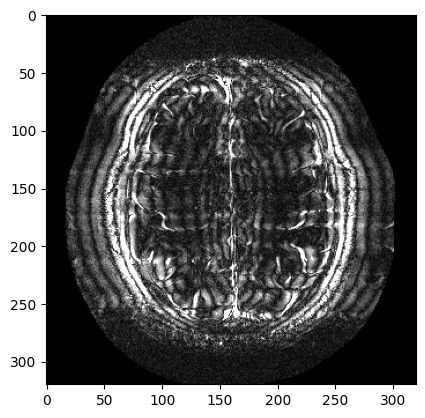

In [ ]:
print("Title error Sense Styl + norm reco  - FS SENSE Style")
plt.imshow(np.abs(image_US_SENSE_Norm - img_8st_slice_sensi_all_coils), cmap='gray')
plt.clim(0,1e-4)

# Perform sense reconstruction with sigpy
[SenseRecon](https://sigpy.readthedocs.io/en/latest/generated/sigpy.mri.app.SenseRecon.html) from sigpy library. <br>
Takes as input sensitivity maps and undersampled kspace for 1 slice and output 1 reconstructed image with multi coil signal recombination

In [ ]:
lambda_reg = 0

# Initialize a list to store the reconstructed images
sense_reconstructions = []
# kspace 4X accelerated and sentivity maps have same shape and coils in 1st dimension
print(kspace_8st_slice_accl.shape)
print(sensitivity_maps_8st_slice.shape)

# Perform SENSE reconstruction for the current echo
sense_recon = app.SenseRecon(
    y = kspace_8st_slice_accl,  # Undersampled k-space data for the slice
    mps = sensitivity_maps_8st_slice,  # Coil sensitivity maps
    lamda = lambda_reg,  # Regularization parameter
    device = sp.Device(-1),  # Use CPU (-1) or GPU (e.g., 0 for the first GPU)
    show_pbar = True  # progress bar for each echo
)

# Run the reconstruction and store the result
img_sense = sense_recon.run()
sense_reconstructions.append(img_sense)
sense_reconstructions

# list of 20 lists. 1 for each coil
print(len(sense_reconstructions[0]))
# Convert the list to a NumPy array for easier handling
sense_reconstructions = np.stack(sense_reconstructions, axis=2)
print(sense_reconstructions.shape)

(20, 320, 320)
(20, 320, 320)


SenseRecon: 100%|██████████| 100/100 [00:14<00:00,  6.81it/s, resid=2.63E-10]

320
(320, 320, 1)


In [ ]:
metrics_r4_sense_sigpy = run_all_metrics(img_8st_slice_sensi_all_coils, sense_reconstructions[:,:,0])

Converting ground truth image to magnitude (absolute value)...
Converting predicted image to magnitude (absolute value)...
Calculating MSE...
Calculating NRMSE...
Calculating PSNR...
Calculating SSIM...

METRICS RESULTS
MSE            : 0.0000
NRMSE          : 0.1590
PSNR           : 29.2638
SSIM           : 0.7330



title : SENSE reco: 4x undersampled


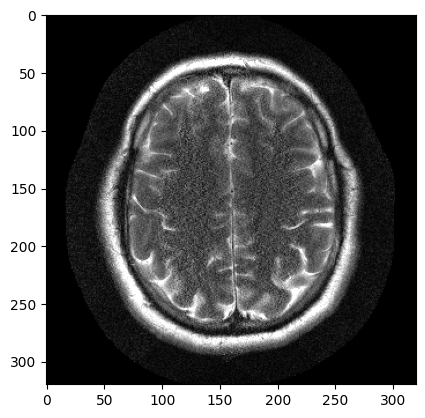

(320, 320)
sense_reconstructions[:,:,0].shape : (320, 320)
sigpy SENSE RMSE compare sensitivity combination:  21.959575499643574  %
zero fill RMSE rss ref:  132.19797010644425  %
NRMSE R4 Sensitivity + normref FS img sense style: 0.354 %'
RMSE R4 Sensitivity + norm ref FS img sense style: 0.0000 '
RMSE R4 Sensitivity + norm ref FS rss: 0.0000 '
Title error Sense sigpy reco  - FS SENSE Style


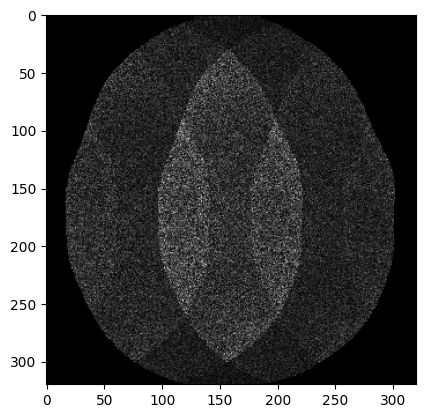

In [ ]:
# Display the reconstructed echoes
print("title : SENSE reco: 4x undersampled")
plt.imshow(np.abs(sense_reconstructions[:,:,0]), cmap='gray')
plt.clim(0,5e-4)
plt.show()
print(sense_reconstructions[:,:,0].shape)
print(f"sense_reconstructions[:,:,0].shape : {sense_reconstructions[:,:,0].shape}")

# compute rmse from sigpy sense recon
rmse_sigpy = nrmse(sense_reconstructions[:,:,0], img_8st_slice_sensi_all_coils)
print('sigpy SENSE RMSE compare sensitivity combination: ', rmse_sigpy, ' %')

# calculate the Root Mean Squared Error with rss as ref
rmse_sigpy_ref_rss = nrmse(sense_reconstructions[:,:,0], img_8st_slice_rss)
print('zero fill RMSE rss ref: ', rmse_sigpy_ref_rss, ' %')

# def calculate_nrmse(actual, predicted):
nrmse_r4_sigpy = calculate_nrmse(img_8st_slice_sensi_all_coils, sense_reconstructions[:,:,0])
print(f"NRMSE R4 Sensitivity + normref FS img sense style: {nrmse_r4_sigpy:.3f} %'")

# def calculate_rmse(actual, predicted):
rmse_r4_sigpy = calculate_rmse(img_8st_slice_sensi_all_coils, sense_reconstructions[:,:,0])
print(f"RMSE R4 Sensitivity + norm ref FS img sense style: {rmse_r4_sigpy:.4f} '")

# def calculate_rmse(actual, predicted):
rmse_r4_sigpy_rss_ctl = calculate_rmse(img_8st_slice_rss, sense_reconstructions[:,:,0])
print(f"RMSE R4 Sensitivity + norm ref FS rss: {rmse_r4_sigpy:.4f} '")

print("Title error Sense sigpy reco  - FS SENSE Style")
plt.imshow(np.abs(sense_reconstructions[:,:,0] - img_8st_slice_sensi_all_coils), cmap='gray')
plt.clim(0,2e-4)


# Simple gradient descent sense reconstruction for comparison
Purpose: solve the linear least-squares SENSE problem (reconstruct a single image x from undersampled multi-coil k-space) by gradient descent on ||A x - y||_2^2, where A applies per-coil sensitivity maps, 2D FFT, and the sampling mask. 
Goal: find image x that makes the forward model A(x) match measured k-space y by minimizing least-squares error: minimize ||A(x) − y||_2^2.

Key variables:

num_iters, step_size: number of GD iterations and the step size (learning rate).<br>
sensitivity_maps_8st_slice: sensitivity maps with shape (nCoils, nx, ny). <br>
cs = np.conj(sensitivity_maps_8st_slice): complex conjugate of coil sensitivities (used in adjoint). <br>
x = img_8stslice_acc_sensi_all_coils[np.newaxis,... ]: current image estimate, shaped (1, nx, ny) to broadcast across coils.<br>
msk: sampling mask (broadcastable to coil dimension) after shifting coil dimension first.<br>
kspace_8st_slice_accl: measured undersampled k-space (shape (nCoils, nx, ny)).<br>
img_8st_slice_sensi_all_coils: ground-truth combined image for comparison.<br>
Per-iteration operations (inside loop): <br>

Forward model: compute predicted undersampled k-space for current x:
x * sensitivity_maps_8st_slice → per-coil images (broadcast to (nCoils, nx, ny)).
ft2_np → per-coil k-space.
multiply by msk → apply undersampling.
residual: res = msk * fft2call(...) - kspace_8st_slice_accl = A x - y.   (fft2call has been replaced by ft2_np)
Adjoint (compute gradient): bring residual back to image domain and combine coils:
inverse_fft2_shift_1slice(res)  → per-coil image-domain residuals.    ifft2call replace by inverse_fft2_shift_1slice
multiply by cs (conj sensitivities) and sum over coils:
tmp = np.sum(cs * inverse_fft2_shift_1slice(res), 2) gives A^H (A x - y) with shape (nx, ny).

Gradient step:
x = x - step_size * tmp[..., np.newaxis] updates the estimate (keeps coil axis).
After loop:

img_recon = x[:,:,0] extracts the reconstructed 2D image.
nrmse(img_recon, img_8st_slice_sensi_all_coils) computes normalized RMSE (percentage) against the reference img_8st_slice_sensi_all_coils.
Interpretation / math (compact):

A(x) = msk * FFT2( x * s ), gradient = A^H(A x - y), update: x ← x − α A^H(A x − y).
Uses magnitudes for complex arithmetic where appropriate (conjugation aligns coil phases).
Caveats / notes:

This is an unregularized least-squares GD (no Tikhonov or sparsity terms).
Convergence and quality depend on step_size; too large can diverge.img_8st_slice_sensi_all_coils
ft2_np / inverse_fft2_shift_1slice include shifting/normalization—so A and A^H are implemented consistently here.


Completed iteration 10/100 
Completed iteration 20/100 
Completed iteration 30/100 
Completed iteration 40/100 
Completed iteration 50/100 
Completed iteration 60/100 
Completed iteration 70/100 
Completed iteration 80/100 
Completed iteration 90/100 
Completed iteration 100/100 
title : SENSE Gradient descent 4x undersampled


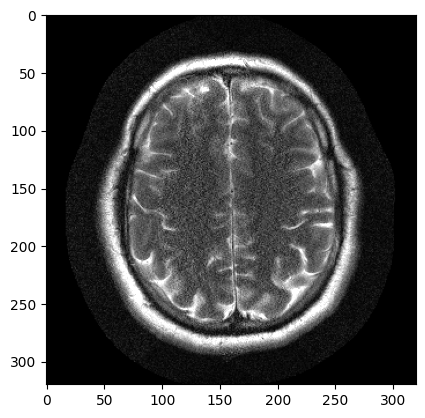

gradient descend 4x accelerated RMSE ref FS sensitivity: 20.782 %'
NRMSE R4 Sensitivity + normref FS img sense style: 0.335 '
RMSE R4 Sensitivity + norm ref FS img sense style: 0.0000 '
title : Error SENSE Gradient descent 4x undersampled vs FS


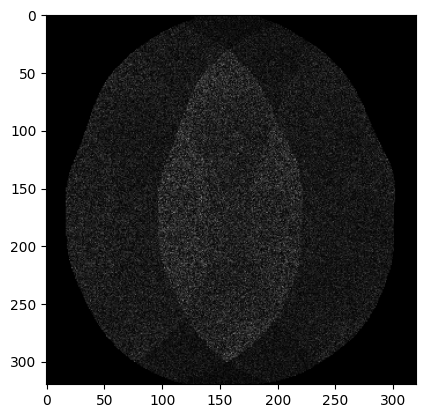

In [ ]:
num_iters = 100 # number of iterations for gradient descent
step_size = 2   # gradient descent step size 

cs = np.conj(sensitivity_maps_8st_slice)  # Conjugate of the sensitivity maps

x = img_8stslice_acc_sensi_all_coils    # Initialize x with the image accelerated 4X reconstruction w/ sensitivity
x = x[np.newaxis,...]   # add axis in 0th dimension

for j in range(num_iters):
    # Display iteration number every 10 iterations
    if (j + 1) % 10 == 0:
        print(f"Completed iteration {j + 1}/{num_iters} ")

    # Ax-b; mismatch
    res = np.transpose(msk, (2,0,1)) * ft2_np(x * sensitivity_maps_8st_slice) - kspace_8st_slice_accl

    # x = x - step_size * A'(Ax-b)
    tmp = np.sum(cs * inverse_fft2_shift_1slice(res), 0)
    x = x - step_size * tmp[np.newaxis,...] 
img_recon = x[0,:,:]

# Display the reconstructed image
print("title : SENSE Gradient descent 4x undersampled")
plt.imshow(np.abs(img_recon), cmap='gray')
plt.clim(0,5e-4)
plt.show()

 
# compute nrmse for gradient descent
rmse_grad = nrmse(img_recon, img_8st_slice_sensi_all_coils)
print(f"gradient descend 4x accelerated RMSE ref FS sensitivity: {rmse_grad:.3f} %'")

# def calculate_nrmse(actual, predicted):
nrmse_r4_grad = calculate_nrmse(img_8st_slice_sensi_all_coils, img_recon)
print(f"NRMSE R4 Sensitivity + normref FS img sense style: {nrmse_r4_grad:.3f} '")

# def calculate_rmse(actual, predicted):
rmse_r4_grad = calculate_rmse(img_8st_slice_sensi_all_coils, img_recon)
print(f"RMSE R4 Sensitivity + norm ref FS img sense style: {rmse_r4_grad:.4f} '")

# Display the error
print("title : Error SENSE Gradient descent 4x undersampled vs FS")
plt.imshow(np.abs(img_recon - img_8st_slice_sensi_all_coils), cmap='gray')
plt.clim(0,3e-4)
plt.show()



In [ ]:
#sensitivity image as ref
metrics_r4_sense_sigpy = run_all_metrics(img_8st_slice_sensi_all_coils, img_recon)
print("rss as ref")
metrics_r4_sense_sigpy = run_all_metrics(img_8st_slice_rss, img_recon)

Converting ground truth image to magnitude (absolute value)...
Converting predicted image to magnitude (absolute value)...
Calculating MSE...
Calculating NRMSE...
Calculating PSNR...
Calculating SSIM...

METRICS RESULTS
MSE            : 0.0000
NRMSE          : 0.1504
PSNR           : 29.7496
SSIM           : 0.7448

rss as ref
Converting predicted image to magnitude (absolute value)...
Calculating MSE...
Calculating NRMSE...
Calculating PSNR...
Calculating SSIM...

METRICS RESULTS
MSE            : 0.0000
NRMSE          : 0.2008
PSNR           : 26.9421
SSIM           : 0.5284



## Gradient descent and plot NRMSE at each iteration

Completed iteration 10/40
Completed iteration 20/40
Completed iteration 30/40
Completed iteration 40/40


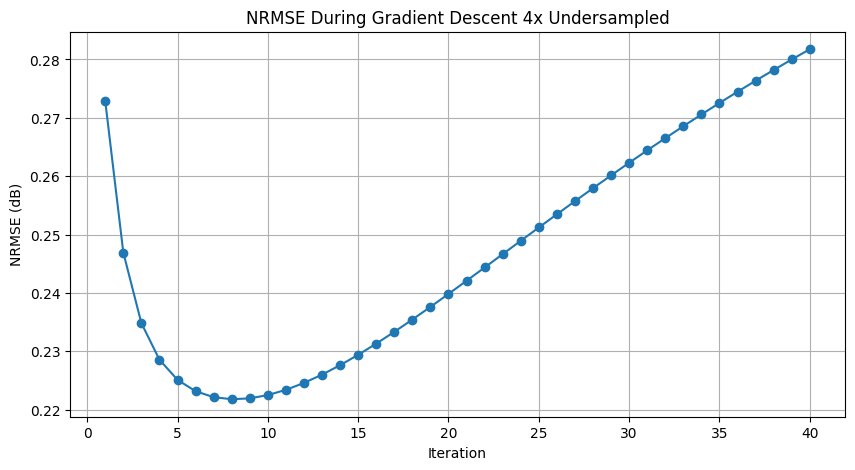

title : SENSE Gradient descent 4x undersampled


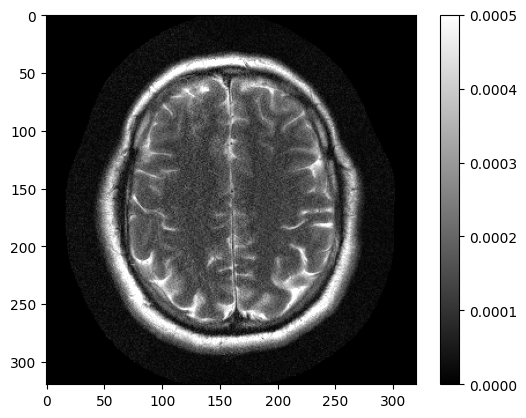

Gradient descent 4x accelerated RMSE ref FS sensitivity: 17.470 %'
NRMSE R4 Sensitivity + normref FS img sense style: 0.282'
NRMSE R4 Sensitivity + normref FS RSS: 1.777'
RMSE R4 Sensitivity + norm ref FS rsensi: 0.0000 '
RMSE R4 Sensitivity + norm ref FS rss: 0.0002 '
title : Error SENSE Gradient descent 4x undersampled vs FS


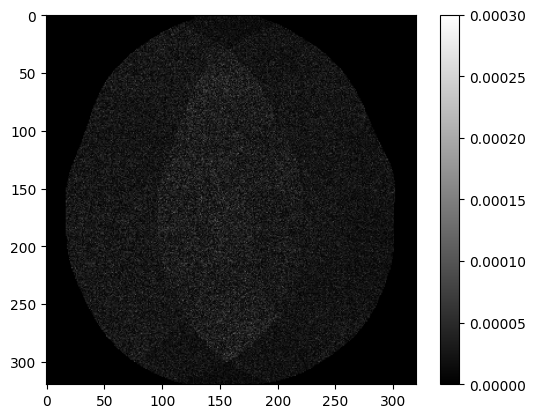

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


# Number of iterations for gradient descent
num_iters = 40  # number of iterations for gradient descent
step_size = 2   # gradient descent step size

# Conjugate of the sensitivity maps
cs = np.conj(sensitivity_maps_8st_slice)  # Conjugate of the sensitivity maps

# Initialize x with the image accelerated 4X reconstruction w/ sensitivity
x = img_8stslice_acc_sensi_all_coils    # Initialize x with the image accelerated 4X reconstruction w/ sensitivity
x = x[np.newaxis, ..., :]   # add axis in 0th dimension

# List to store NRMSE values
nrmse_values = []

for j in range(num_iters):
    # Display iteration number every 10 iterations
    if (j + 1) % 10 == 0:
        print(f"Completed iteration {j + 1}/{num_iters}")

    # Ax-b; mismatch
    res = np.transpose(msk, (2, 0, 1)) * ft2_np(x * sensitivity_maps_8st_slice) - kspace_8st_slice_accl

    # x = x - step_size * A'(Ax-b)
    tmp = np.sum(cs * inverse_fft2_shift_1slice(res), 0)
    x = x - step_size * tmp[np.newaxis, ..., :] 

    # Calculate NRMSE for the current iteration
    img_recon = x[0, :, :]
    rmse_grad = calculate_nrmse(img_8st_slice_sensi_all_coils, img_recon)
    nrmse_values.append(rmse_grad)

# Plot the NRMSE over iterations
plt.figure(figsize=(10, 5))
plt.plot(range(1, num_iters + 1), np.abs(nrmse_values), marker='o')
plt.xlabel('Iteration')
plt.ylabel('NRMSE (dB)')
plt.title('NRMSE During Gradient Descent 4x Undersampled')
plt.grid(True)
plt.show()

# Display the reconstructed image
print("title : SENSE Gradient descent 4x undersampled")
plt.imshow(np.abs(img_recon), cmap='gray')
plt.colorbar()
plt.clim(0, 5e-4)
plt.show()

# Compute nrmse for gradient descent
rmse_grad = nrmse(img_recon, img_8st_slice_sensi_all_coils)
print(f"Gradient descent 4x accelerated RMSE ref FS sensitivity: {rmse_grad:.3f} %'")

# def calculate_nrmse(actual, predicted):
nrmse_r4_grad = calculate_nrmse(img_8st_slice_sensi_all_coils, img_recon)
print(f"NRMSE R4 Sensitivity + normref FS img sense style: {nrmse_r4_grad:.3f}'")

# def calculate_nrmse(actual, predicted):
nrmse_r4_grad_rss_ctl = calculate_nrmse(img_8st_slice_rss, img_recon)
print(f"NRMSE R4 Sensitivity + normref FS RSS: {nrmse_r4_grad_rss_ctl:.3f}'")

# def calculate_rmse(actual, predicted):
rmse_r4_grad_sensi_ctl = calculate_rmse(img_8st_slice_sensi_all_coils, img_recon)
print(f"RMSE R4 Sensitivity + norm ref FS rsensi: {rmse_r4_grad_sensi_ctl:.4f} '")

# def calculate_rmse(actual, predicted):
rmse_r4_grad = calculate_rmse(img_8st_slice_rss, img_recon)
print(f"RMSE R4 Sensitivity + norm ref FS rss: {rmse_r4_grad:.4f} '")

# Display the error
print("title : Error SENSE Gradient descent 4x undersampled vs FS")
plt.imshow(np.abs(img_recon - img_8st_slice_sensi_all_coils), cmap='gray')
plt.colorbar()
plt.clim(0, 3e-4)
plt.show()

# Wavelet regularized reconstruction: sigpy 

## L1 wavelet regularization

In [ ]:
# Parameters for L1 wavelet reconstruction
lambda_wavelet = 2e-6  # Regularization parameter for wavelet sparsity

    
# Perform L1 Wavelet reconstruction
l1_wavelet_recon = app.L1WaveletRecon(
    y = kspace_8st_slice_accl,  # Undersampled k-space data
    mps = kspace_8st_slice_accl,  # Coil sensitivity maps
    lamda = lambda_wavelet,  # Regularization parameter
    device = sp.Device(-1),  # Use CPU (-1) or GPU (e.g., 0 for the first GPU)
    show_pbar = True  # Show progress bar
)

# Run the reconstruction and store the result
img_l1_wavelet = l1_wavelet_recon.run()

non_zero_mask = np.abs(kspace_8st_slice_accl[8,:,:]) > 0

# apply the non-zero mask to the reconstructed image
l1_wavelet_reconstructions = img_l1_wavelet * non_zero_mask

# Display the reconstructed echoes

show_1_2D_img(l1_wavelet_reconstructions, "L1 wavelet")
show_1_2D_img(np.abs(l1_wavelet_reconstructions - img_8st_slice_sensi_all_coils), "L1 wavelet error")

# compute rmse from sigpy wavelet recon
rmse_wavelet = nrmse(l1_wavelet_reconstructions, img_8st_slice_sensi_all_coils)

print('sigpy wavelet RMSE: ', rmse_wavelet, ' %')

#mosaic(2*np.abs(l1_wavelet_reconstructions - img_8st_slice_sensi_all_coils), 1, 1, 5, [0, 3e-4], '2x wavelet error', 0, 0)
#sensitivity image as ref
metrics_r4_sense_sigpy = run_all_metrics(img_8st_slice_sensi_all_coils, l1_wavelet_reconstructions)


NameError: name 'kspace_8st_slice_accl' is not defined

In [ ]:


# Parameters for L1 wavelet reconstruction
lambda_wavelet = 2e-6  # Regularization parameter for wavelet sparsity

    
# Perform L1 Wavelet reconstruction
l1_wavelet_recon = app.L1WaveletRecon(
    y = kspace_use,  # Undersampled k-space data
    mps = sens,  # Coil sensitivity maps
    lamda = lambda_wavelet,  # Regularization parameter
    device = sp.Device(-1),  # Use CPU (-1) or GPU (e.g., 0 for the first GPU)
    show_pbar = True  # Show progress bar
)

# Run the reconstruction and store the result
img_l1_wavelet = l1_wavelet_recon.run()

non_zero_mask = np.abs(sensitivity_maps[:,:,0]) > 0

# apply the non-zero mask to the reconstructed image
l1_wavelet_reconstructions = img_l1_wavelet * non_zero_mask

# Display the reconstructed echoes
mosaic(np.abs(l1_wavelet_reconstructions), 1, 1, 4, [0, 5e-4], 'L1 Wavelet Recon', 0, 0)


# compute rmse from sigpy wavelet recon
rmse_wavelet = nrmse(l1_wavelet_reconstructions, img_8st_slice_sensi_all_coils)

print('sigpy wavelet RMSE: ', rmse_wavelet, ' %')

mosaic(2*np.abs(l1_wavelet_reconstructions - img_8st_slice_sensi_all_coils), 1, 1, 5, [0, 3e-4], '2x wavelet error', 0, 0)


AttributeError: 'tuple' object has no attribute 'dtype'

In [ ]:


# Parameters for L1 wavelet reconstruction
lambda_wavelet = 2e-6  # Regularization parameter for wavelet sparsity

    
# Perform L1 Wavelet reconstruction
l1_wavelet_recon = app.L1WaveletRecon(
    y = kspace_use,  # Undersampled k-space data
    mps = sens,  # Coil sensitivity maps
    lamda = lambda_wavelet,  # Regularization parameter
    device = sp.Device(-1),  # Use CPU (-1) or GPU (e.g., 0 for the first GPU)
    show_pbar = True  # Show progress bar
)

# Run the reconstruction and store the result
img_l1_wavelet = l1_wavelet_recon.run()

non_zero_mask = np.abs(sensitivity_maps[:,:,0]) > 0

# apply the non-zero mask to the reconstructed image
l1_wavelet_reconstructions = img_l1_wavelet * non_zero_mask

# Display the reconstructed echoes
mosaic(np.abs(l1_wavelet_reconstructions), 1, 1, 4, [0, 5e-4], 'L1 Wavelet Recon', 0, 0)


# compute rmse from sigpy wavelet recon
rmse_wavelet = nrmse(l1_wavelet_reconstructions, img_8st_slice_sensi_all_coils)

print('sigpy wavelet RMSE: ', rmse_wavelet, ' %')

mosaic(2*np.abs(l1_wavelet_reconstructions - img_8st_slice_sensi_all_coils), 1, 1, 5, [0, 3e-4], '2x wavelet error', 0, 0)


AttributeError: 'tuple' object has no attribute 'dtype'

## Total variation regularized reconstruction 
https://sigpy.readthedocs.io/en/latest/generated/sigpy.mri.app.TotalVariationRecon.html#sigpy.mri.app.TotalVariationRecon

MaxEig:   0%|          | 0/30 [00:00<?, ?it/s]

TotalVariationRecon: 100%|██████████| 100/100 [00:21<00:00,  4.61it/s, resid=7.68E-05]


sigpy wavelet RMSE:  12.32069799351479  %


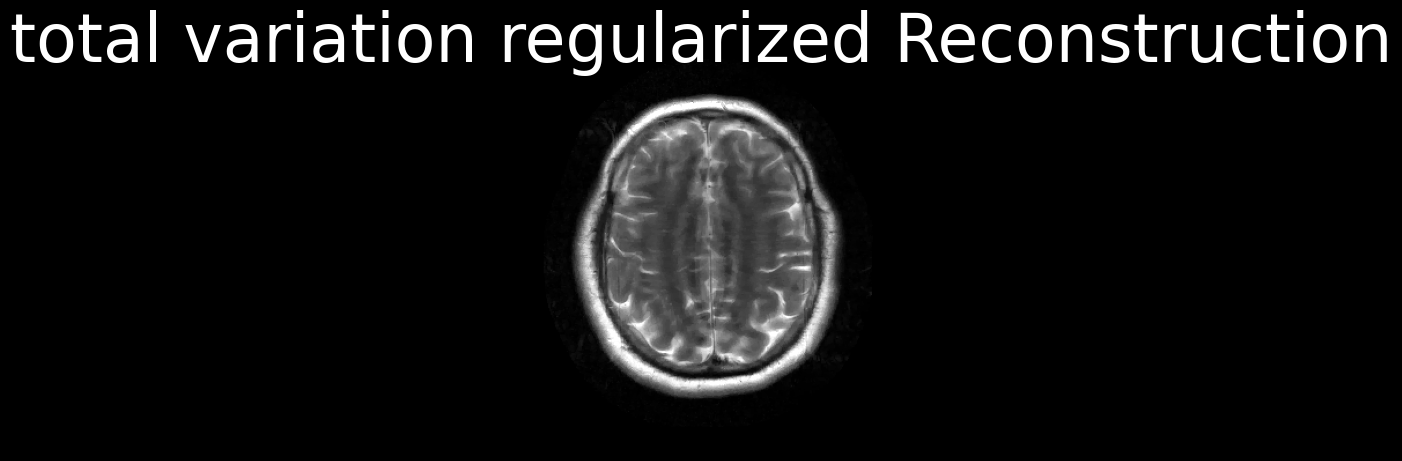

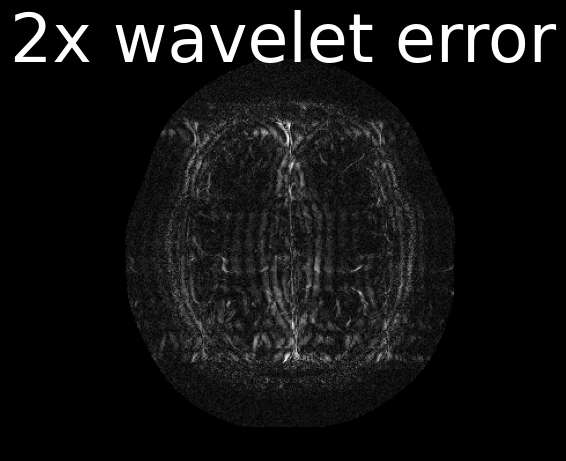

In [ ]:


# Parameters for L1 wavelet reconstruction
lambda_wavelet = 2e-6  # Regularization parameter 
    
# Perform total variation regularized reconstruction
total_variation_recon = app.TotalVariationRecon(
    y = kspace_use,  # Undersampled k-space data
    mps = sens,  # Coil sensitivity maps
    lamda = lambda_wavelet,  # Regularization parameter
    device = sp.Device(-1),  # Use CPU (-1) or GPU (e.g., 0 for the first GPU)
    show_pbar = True  # Show progress bar
)

# Run the reconstruction and store the result
img_total_variation = total_variation_recon.run()

non_zero_mask = np.abs(sensitivity_maps_8st_slice[:,:,0]) > 0

# apply the non-zero mask to the reconstructed image
total_variation_reconstructions = img_total_variation * non_zero_mask

# Display the reconstructed echoes
mosaic(np.abs(total_variation_reconstructions), 1, 1, 4, [0, 5e-4], 'total variation regularized Reconstruction', 0, 0)


# compute rmse from sigpy wavelet recon
rmse_wavelet = nrmse(total_variation_reconstructions, img_8st_slice_sensi_all_coils)

print('sigpy wavelet RMSE: ', rmse_wavelet, ' %')

mosaic(2*np.abs(total_variation_reconstructions - img_8st_slice_sensi_all_coils), 1, 1, 5, [0, 3e-4], '2x wavelet error', 0, 0)
